# Main 08 — circle diagrams

Create the four formal 26-node/168-edge cross-sectional circle diagrams and run reproducibility checks.

- Formal analysis universe: 12 cortical + 14 limbic ROIs (26 nodes)
- Cross-network connectivity: 12 × 14 = 168 edges
- Pipeline: `main`; step 8 of 10
- Run mode: standalone; all prerequisite steps load automatically in the same kernel.


In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)
_run_step("main_01_setup_load.py")
_run_step("main_02_demographics_hc_reference.py")
_run_step("main_03_baseline_discovery_sensitivity.py")
_run_step("main_04_longitudinal_paired_clinical.py")
_run_step("main_05_interactions_mwc.py")
_run_step("main_06_spatial_replication_report.py")
_run_step("main_07_core_figures_heatmaps.py")


MetaFL package root: .
Main-analysis output root: ./outputs/main_analyses
Cortical IDs: [3, 4, 5, 6, 19, 20, 21, 22, 25, 26, 31, 32]
Limbic IDs: [41, 42, 43, 44, 45, 46, 75, 76, 77, 78, 79, 80, 151, 152]
Cross-edge family: 168


,cohort,clinical_n,ses01_complete_n
0,HC,23,23
1,nTRD,25,25
2,TRD1,35,35
3,TRD2,104,104


,cohort,baseline_n,metric
0,nTRD,25,age/sex-adjusted normative-SC MwC deviation z
1,TRD1,35,age/sex-adjusted normative-SC MwC deviation z
2,TRD2,104,age/sex-adjusted normative-SC MwC deviation z


Written: ./outputs/main_analyses/demographic_and_clinical_summary.xlsx


,variable,HC,nTRD,TRD1,TRD2,primary_test,primary_p_value,TRD1_vs_TRD2_test,TRD1_vs_TRD2_p_value
0,Age,50.91 (17.04); n=23,52.32 (12.22); n=25,48.20 (15.52); n=35,39.09 (13.96); n=104,"one-way ANOVA: HC, nTRD, TRD1",0.561396,Welch t-test,0.003261
1,"Female, n (%)",14 (60.87%); n=23,14 (56.00%); n=25,25 (71.43%); n=35,73 (70.19%); n=104,"Pearson chi-square: HC, nTRD, TRD1",0.443311,Fisher exact test,1.000000
2,Education,14.17 (3.46); n=23,13.44 (3.86); n=25,13.14 (3.83); n=35,14.57 (2.81); n=104,"one-way ANOVA: HC, nTRD, TRD1",0.587829,Welch t-test,0.048544


...

Combined workbook: ./outputs/main_analyses/all_reported_results.xlsx


,analysis,family_or_tested_n,reporting_rule,reported_n
0,TRD1 vs nTRD edge,168,uncorrected p<0.01,22
1,TRD1 vs nTRD regional,26,uncorrected p<0.01,7
2,HDRS-adjusted sensitivity edge,168,uncorrected p<0.01,2
3,HDRS-adjusted sensitivity regional,26,uncorrected p<0.01,2
4,iTBS edge pre-post,168,paired uncorrected p<0.05,12
5,iTBS edge HDRS,12,BH-FDR q<0.05 primary,0
6,iTBS edge HDRS,12,uncorrected p<0.05 exploratory,0
7,iTBS regional pre-post,26,paired uncorrected p<0.05,0
8,iTBS regional HDRS,0,BH-FDR q<0.05 primary,0
9,iTBS regional HDRS,0,uncorrected p<0.05 exploratory,0


Regional heatmap: ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_regional26_strip_heatmap.png
MwC heatmap (same renderer): ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap.png
MwC heatmap input values: ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap_input_values.csv
Connectivity heatmap: ./outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_corticolimbic12x14_heatmap.png


TRD2 pre-post raincloud: ./outputs/main_analyses/04_figures/TRD2_prepost_raincloud.png
Canonical green HDRS correlation panel (partial Spearman; age/sex): ./outputs/main_analyses/04_figures/TRD2_prepost_HDRS_correlation_panel_green_reference.png


,panel_position,arm,feature_label,ROI_1,ROI_2,partial_Spearman_r_age_sex,partial_Spearman_p_age_sex,n_used,covariates,BH_FDR_q_across_displayed_edges,uncorrected_p_lt_0p05,BH_FDR_q_lt_0p05
0,1,rTMS,Rt.vmPFC-Rt.PUT,AAL3_022_Frontal_Med_Orb_R,AAL3_078_Putamen_R,0.103936,0.571327,34,age; sex,0.692297,False,False
1,2,rTMS,Rt.mOFC-Rt.PUT,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,0.066153,0.719055,34,age; sex,0.719055,False,False
2,3,rTMS,Rt.mOFC-Rt.PAL,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,0.389852,0.027405,34,age; sex,0.164432,True,False
3,4,iTBS,Lt.dmPFC-Lt.PAL,AAL3_019_Frontal_Sup_Medial_L,AAL3_079_Pallidum_L,0.097622,0.576914,37,age; sex,0.692297,False,False
4,5,iTBS,Lt.lOFC-Lt.HPC,AAL3_031_OFClat_L,AAL3_041_Hippocampus_L,0.210360,0.225153,37,age; sex,0.675458,False,False
5,6,iTBS,Lt.lOFC-Lt.SGC,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,-0.151338,0.385489,37,age; sex,0.692297,False,False


## Preamble


In [2]:
"""Auto-extracted pipeline step: Main 08 — circle diagrams and reproducibility checks.

Do not edit generated copies independently of the source notebooks.
"""


'Auto-extracted pipeline step: Main 08 — circle diagrams and reproducibility checks.\n\nDo not edit generated copies independently of the source notebooks.\n'

## Source 36


In [3]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import PathPatch, Wedge
from matplotlib.path import Path as MplPath

# Mean-deviation vectors; all panels retain the same ROI and edge ordering.
circular_panels = {
    "nonTRD deviation": {
        "regional": trd1_result["ntrd_regional"].to_numpy(float).mean(axis=0),
        "edge": trd1_result["ntrd_edge"].mean(axis=0),
        "regional_mask": None,
        "edge_mask": None,
        "stem": "nonTRD_mean_deviation",
    },
    "TRD1 deviation": {
        "regional": trd1_result["case_regional"].to_numpy(float).mean(axis=0),
        "edge": trd1_result["case_edge"].mean(axis=0),
        "regional_mask": None,
        "edge_mask": None,
        "stem": "TRD1_mean_deviation",
    },
    "TRD2 deviation": {
        "regional": trd2_context["case_regional"].to_numpy(float).mean(axis=0),
        "edge": trd2_context["case_edge"].mean(axis=0),
        "regional_mask": None,
        "edge_mask": None,
        "stem": "TRD2_mean_deviation",
    },
    "TRD versus nonTRD": {
        "regional": (
            trd1_result["case_regional"].to_numpy(float).mean(axis=0)
            - trd1_result["ntrd_regional"].to_numpy(float).mean(axis=0)
        ),
        "edge": (
            trd1_result["case_edge"].mean(axis=0)
            - trd1_result["ntrd_edge"].mean(axis=0)
        ),
        "regional_mask": None,
        "edge_mask": None,
        "stem": "TRD1_vs_nonTRD_all",
    },
}

# Shared scales permit direct visual comparison across all four panels.
circular_node_vmax = float(np.nanquantile(np.abs(np.concatenate([
    item["regional"] for item in circular_panels.values()
])), 0.98))
circular_edge_vmax = float(np.nanquantile(np.abs(np.concatenate([
    item["edge"] for item in circular_panels.values()
])), 0.98))

# Nature-oriented, color-vision-conscious red/blue pairing.
CIRCULAR_NEGATIVE = "#2868A8"
CIRCULAR_POSITIVE = "#B64040"
CIRCULAR_NEUTRAL = "#F7F7F5"
CIRCULAR_GRAPHITE = "#30343B"
CIRCULAR_GUIDE = "#B8C0C8"
circular_cmap = LinearSegmentedColormap.from_list(
    "ibsc_nature_diverging",
    [CIRCULAR_NEGATIVE, "#C9DCEC", CIRCULAR_NEUTRAL, "#EBC9C3", CIRCULAR_POSITIVE],
    N=256,
)
circular_norm = TwoSlopeNorm(
    vmin=-circular_node_vmax, vcenter=0, vmax=circular_node_vmax
)

# Top semicircle: cortical; bottom semicircle: limbic.
cortical_angles = np.linspace(170, 10, len(CORTICAL_ROIS))
limbic_angles = np.linspace(190, 350, len(LIMBIC_ROIS))
roi_angles = {
    **dict(zip(CORTICAL_ROIS, cortical_angles)),
    **dict(zip(LIMBIC_ROIS, limbic_angles)),
}
roi_positions = {
    roi: np.array([np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle))])
    for roi, angle in roi_angles.items()
}
regional_index = {roi: index for index, roi in enumerate(ROI_COLUMNS)}
edge_index = {tuple(edge): index for index, edge in enumerate(CROSS_EDGE_NAMES)}


def draw_corticolimbic_connectogram(
    ax, title, regional_values, edge_values,
    regional_mask=None, edge_mask=None, panel_letter=None,
):
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_xlim(-1.52, 1.52)
    ax.set_ylim(-1.53, 1.63)
    ax.set_facecolor("white")

    # Quiet guide arcs separate node rings from the edge field.
    for start, end in [(5, 175), (185, 355)]:
        ax.add_patch(Wedge(
            (0, 0), 0.985, start, end, width=0.008,
            facecolor=CIRCULAR_GUIDE, edgecolor="none", zorder=0,
        ))

    # Draw weaker edges first so the strongest effects remain visible.
    visible_edges = []
    for edge, index in edge_index.items():
        value = float(edge_values[index])
        visible = edge_mask is None or edge in edge_mask
        if visible and np.isfinite(value) and abs(value) > 0:
            visible_edges.append((abs(value), edge[0], edge[1], value))
    visible_edges.sort()

    for magnitude, roi_1, roi_2, value in visible_edges:
        strength = min(magnitude / circular_edge_vmax, 1.0)
        color = CIRCULAR_POSITIVE if value > 0 else CIRCULAR_NEGATIVE
        start = roi_positions[roi_1] * 0.965
        end = roi_positions[roi_2] * 0.965
        path = MplPath(
            [start, start * 0.30, end * 0.30, end],
            [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4],
        )
        ax.add_patch(PathPatch(
            path, facecolor="none", edgecolor=color,
            linewidth=0.28 + 1.00 * strength,
            alpha=0.09 + 0.48 * strength,
            zorder=1, capstyle="round",
        ))

    # Ring segments encode regional deviation using the same signed palette.
    for roi in CORTICAL_ROIS + LIMBIC_ROIS:
        angle = roi_angles[roi]
        value = float(regional_values[regional_index[roi]])
        visible = regional_mask is None or roi in regional_mask
        facecolor = (
            circular_cmap(circular_norm(np.clip(value, -circular_node_vmax, circular_node_vmax)))
            if visible else "#ECEFF1"
        )
        ax.add_patch(Wedge(
            (0, 0), 1.13, angle - 4.3, angle + 4.3, width=0.125,
            facecolor=facecolor, edgecolor="white", linewidth=0.8, zorder=4,
        ))

        # Signed anchor tick provides redundant encoding beyond ring color.
        tick_color = (
            CIRCULAR_POSITIVE if value > 0 else CIRCULAR_NEGATIVE
        ) if visible else "#B7BEC5"
        direction = np.array([
            np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle))
        ])
        tick_start, tick_end = direction * 0.925, direction * 0.985
        ax.plot(
            [tick_start[0], tick_end[0]], [tick_start[1], tick_end[1]],
            color=tick_color, linewidth=1.05, alpha=0.85, zorder=3,
        )

        # Radial labels avoid the central overlap produced by tangential labels.
        label_radius = 1.27
        x, y = label_radius * direction
        rotation = angle + (180 if 90 < angle < 270 else 0)
        horizontal_alignment = "right" if direction[0] < 0 else "left"
        ax.text(
            x, y, roi_short_label(roi),
            rotation=rotation, rotation_mode="anchor",
            ha=horizontal_alignment, va="center",
            fontsize=6.9, fontweight="semibold", color=CIRCULAR_GRAPHITE,
            zorder=5,
        )

    ax.set_title(title, fontsize=11, fontweight="bold", color="#22272E", pad=14)
    if panel_letter:
        ax.text(
            -1.47, 1.42, panel_letter,
            ha="left", va="top", fontsize=13, fontweight="bold", color="#111111",
        )


# Raw plotting data and explicit display masks.
node_rows, edge_rows = [], []
edge_stats_lookup = trd1_result["edge_all"].set_index(["ROI_1", "ROI_2"])
regional_stats_lookup = trd1_result["regional_all"].set_index("ROI")
for panel, item in circular_panels.items():
    for roi in ROI_COLUMNS:
        row = {
            "panel": panel,
            "network": "cortical" if roi in CORTICAL_ROIS else "limbic",
            "ROI": roi,
            "label": roi_short_label(roi),
            "value": float(item["regional"][regional_index[roi]]),
            "displayed": item["regional_mask"] is None or roi in item["regional_mask"],
        }
        if panel.startswith("TRD1 −"):
            row["p_group_uncorrected"] = float(regional_stats_lookup.loc[roi, "p_group_uncorrected"])
            row["q_fdr_BH_audit_only"] = float(regional_stats_lookup.loc[roi, "q_fdr_BH_26_regions_audit_only"])
        node_rows.append(row)
    for edge, index in edge_index.items():
        row = {
            "panel": panel,
            "ROI_1": edge[0],
            "ROI_2": edge[1],
            "value": float(item["edge"][index]),
            "displayed": item["edge_mask"] is None or edge in item["edge_mask"],
        }
        if panel.startswith("TRD1 −"):
            row["p_group_uncorrected"] = float(edge_stats_lookup.loc[edge, "p_group_uncorrected"])
            row["q_fdr_BH_audit_only"] = float(edge_stats_lookup.loc[edge, "q_fdr_BH_168_edges_audit_only"])
        edge_rows.append(row)

circular_data_file = FIGURE_OUT / "corticolimbic_circular_plot_data.xlsx"
with pd.ExcelWriter(circular_data_file, engine="openpyxl") as writer:
    pd.DataFrame(node_rows).to_excel(writer, sheet_name="regional_nodes", index=False)
    pd.DataFrame(edge_rows).to_excel(writer, sheet_name="connectivity_edges", index=False)
    pd.DataFrame([
        {"parameter": "regional_shared_abs_scale_98pct", "value": circular_node_vmax},
        {"parameter": "edge_shared_abs_scale_98pct", "value": circular_edge_vmax},
        {"parameter": "positive_color", "value": CIRCULAR_POSITIVE},
        {"parameter": "negative_color", "value": CIRCULAR_NEGATIVE},
        {"parameter": "contrast_edge_rule", "value": "All 168 cortico-limbic edges displayed"},
        {"parameter": "contrast_regional_rule", "value": "All 26 regional ROIs displayed"},
    ]).to_excel(writer, sheet_name="plot_settings", index=False)

# Combined wide figure: four panels in one row with generous separation.
fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.6), facecolor="white")
for ax, (title, item) in zip(axes, circular_panels.items()):
    draw_corticolimbic_connectogram(
        ax, title, item["regional"], item["edge"],
        item["regional_mask"], item["edge_mask"],
    )
legend_handles = [
    Line2D(
        [0], [0], color=CIRCULAR_POSITIVE, linewidth=2.0,
        marker="s", markerfacecolor=CIRCULAR_POSITIVE, markeredgecolor="white",
        label="Positive deviation / higher in TRD1",
    ),
    Line2D(
        [0], [0], color=CIRCULAR_NEGATIVE, linewidth=2.0,
        marker="s", markerfacecolor=CIRCULAR_NEGATIVE, markeredgecolor="white",
        label="Negative deviation / lower in TRD1",
    ),
]
fig.legend(
    handles=legend_handles, loc="lower center", ncol=2,
    frameon=False, bbox_to_anchor=(0.5, 0.005), fontsize=8,
)
fig.subplots_adjust(left=0.015, right=0.985, top=0.90, bottom=0.12, wspace=0.28)

circular_summary_png = FIGURE_OUT / "corticolimbic_circular_summary.png"
circular_summary_pdf = FIGURE_OUT / "corticolimbic_circular_summary.pdf"
circular_summary_svg = FIGURE_OUT / "corticolimbic_circular_summary.svg"
fig.savefig(circular_summary_png, dpi=600, facecolor="white", bbox_inches="tight")
fig.savefig(circular_summary_pdf, facecolor="white", bbox_inches="tight")
fig.savefig(circular_summary_svg, facecolor="white", bbox_inches="tight")
plt.close(fig)

# Individual figures preserve label legibility for presentations and supplements.
circular_individual_files = []
for title, item in circular_panels.items():
    fig, ax = plt.subplots(figsize=(4.1, 4.25), facecolor="white")
    draw_corticolimbic_connectogram(
        ax, title, item["regional"], item["edge"],
        item["regional_mask"], item["edge_mask"],
    )
    fig.subplots_adjust(left=0.015, right=0.985, top=0.94, bottom=0.03)
    png = FIGURE_OUT / f"corticolimbic_circular_{item['stem']}.png"
    pdf = FIGURE_OUT / f"corticolimbic_circular_{item['stem']}.pdf"
    fig.savefig(png, dpi=600, facecolor="white", bbox_inches="tight")
    fig.savefig(pdf, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    circular_individual_files.extend([png, pdf])

print("Circular connectogram:", circular_summary_png)
print("Raw plotting data:", circular_data_file)


Circular connectogram: ./outputs/main_analyses/04_figures/corticolimbic_circular_summary.png
Raw plotting data: ./outputs/main_analyses/04_figures/corticolimbic_circular_plot_data.xlsx


## Source 38


In [4]:
# Dynamic reproducibility checks for the high-quality PET-QC TRD2 analysis.
observed_active_results = {
    "TRD1_edge_p_lt_0p01": len(trd1_result["edge_reported"]),
    "TRD1_regional_p_lt_0p01": len(trd1_result["regional_reported"]),
    "iTBS_edge_prepost_p_lt_0p05": len(itbs_result["edge_selected"]),
    "iTBS_regional_prepost_p_lt_0p05": len(itbs_result["regional_selected"]),
    "rTMS_edge_prepost_p_lt_0p05": len(rtms_result["edge_selected"]),
    "rTMS_regional_prepost_p_lt_0p05": len(rtms_result["regional_selected"]),
    "sham_edge_prepost_p_lt_0p05": len(sham_result["edge_selected"]),
    "sham_regional_prepost_p_lt_0p05": len(sham_result["regional_selected"]),
    "active_vs_sham_interaction_p_lt_0p05": len(interaction_p05),
}
assert clinical["analysis_cohort"].value_counts().to_dict() == EXPECTED_COUNTS
assert clinical.loc[clinical["analysis_cohort"] == "TRD2", "analysis_arm"].value_counts().to_dict() == EXPECTED_ARMS
assert trd2_context["case_edge"].shape == (EXPECTED_COUNTS["TRD2"], 168)
assert trd2_context["case_regional"].shape == (EXPECTED_COUNTS["TRD2"], 26)
assert {result["arm"]: result["n"] for result in [itbs_result, rtms_result, sham_result]} == EXPECTED_PAIRED_ARMS
assert len(sensitivity_mwc_all) == 26
assert not (TRD2_OUT / "edge_all.xlsx").exists()
assert not (TRD2_OUT / "regional_all.xlsx").exists()
for output_file in [demographic_file, combined_file, sensitivity_file, interaction_file, spatial_png, spatial_pdf, regional_png, regional_pdf, edge_png, edge_pdf, boxplot_png, boxplot_pdf, correlation_png, correlation_pdf, circular_summary_png, circular_summary_pdf, circular_summary_svg, LONGITUDINAL_EDGE_FILE]:
    assert output_file.exists() and output_file.stat().st_size > 0, output_file
print("High-quality PET-QC TRD2 core analysis reproduced successfully.")
display(pd.DataFrame([observed_active_results]))
display(prepost_counts)
display(interaction_p05)
display(spatial_summary)


High-quality PET-QC TRD2 core analysis reproduced successfully.


,TRD1_edge_p_lt_0p01,TRD1_regional_p_lt_0p01,iTBS_edge_prepost_p_lt_0p05,iTBS_regional_prepost_p_lt_0p05,rTMS_edge_prepost_p_lt_0p05,rTMS_regional_prepost_p_lt_0p05,sham_edge_prepost_p_lt_0p05,sham_regional_prepost_p_lt_0p05,active_vs_sham_interaction_p_lt_0p05
0,22,7,12,0,10,0,7,8,4


,arm,n,edge_prepost_uncorrected_p_lt_0p05,edge_HDRS_FDR_q_lt_0p05_primary,edge_HDRS_uncorrected_p_lt_0p05_exploratory,regional_prepost_uncorrected_p_lt_0p05,regional_HDRS_FDR_q_lt_0p05_primary,regional_HDRS_uncorrected_p_lt_0p05_exploratory
0,iTBS,37,12,0,0,0,0,0
1,rTMS,34,10,0,1,0,0,0
2,sham,33,7,0,0,8,0,0


,active_arm,modality,ROI_1,ROI_2,active_n,active_pre_mean_deviation,active_post_mean_deviation,active_post_minus_pre,active_change_CI95_low,active_change_CI95_high,active_Cohen_dz,active_paired_t,active_paired_p_uncorrected,sham_n,sham_pre_mean_deviation,sham_post_mean_deviation,sham_post_minus_pre,sham_change_CI95_low,sham_change_CI95_high,sham_Cohen_dz,sham_paired_t,sham_paired_p_uncorrected,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_p_uncorrected,interaction_n,interaction_residual_shapiro_W_descriptive,interaction_residual_shapiro_p_descriptive,interaction_breusch_pagan_p_descriptive,interaction_q_fdr_BH_within_arm_modality
0,iTBS,edge,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,37,0.322443,-0.025557,-0.348000,-0.572619,-0.123381,-0.516559,-3.142105,0.003349,33,0.006111,0.071019,0.064908,-0.181350,0.311167,0.093460,0.536889,0.595058,-0.416926,-0.743816,-0.090037,-2.546487,-0.299102,66.0,0.013222,70,0.959085,2.229230e-02,0.955781,0.158664
12,rTMS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,34,-0.273847,0.514968,0.788815,0.318728,1.258902,0.585489,3.413956,0.001712,33,-0.183835,-0.666455,-0.482620,-1.379927,0.414687,-0.190715,-1.095573,0.281443,1.276207,0.296265,2.256148,2.602498,0.311564,63.0,0.011524,67,0.780512,1.271153e-08,0.383674,0.115241
13,rTMS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,34,-0.087030,0.377345,0.464375,0.132766,0.795984,0.488612,2.849074,0.007495,33,-0.324140,-0.963345,-0.639205,-1.564791,0.286381,-0.244874,-1.406696,0.169156,1.106516,0.145622,2.067410,2.301186,0.278456,63.0,0.024701,67,0.653186,2.641524e-11,0.288406,0.123506
14,rTMS,edge,AAL3_026_OFCmed_R,AAL3_077_Putamen_L,34,-0.413277,0.064399,0.477676,0.042754,0.912599,0.383216,2.234515,0.032338,33,-0.661392,-1.178641,-0.517249,-1.405618,0.371120,-0.206455,-1.185996,0.244356,1.009294,0.061628,1.956960,2.128296,0.258991,63.0,0.037230,67,0.816532,1.100567e-07,0.286198,0.124102


,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,104,26,Pearson correlation,0.973450,7.072936e-17,9.999900e-06,0.007145,0.468580,0.468581,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Regional SUVR,35,104,26,Same-direction proportion,0.961538,NaN,9.999900e-05,0.505726,0.730769,0.807692,>=,True,True,25.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Regional,Regional SUVR,35,104,26,Magnitude-weighted signed DSC,0.706271,NaN,9.999900e-06,0.295898,0.467967,0.467969,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
3,Connectivity,Metabolic edge,35,104,168,Pearson correlation,0.800049,1.127070e-38,5.511464e-07,0.070418,0.283198,0.283198,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
4,Connectivity,Metabolic edge,35,104,168,Same-direction proportion,0.910714,NaN,5.522487e-04,0.838435,0.875000,0.886905,>=,True,True,153.0,3628800,True,NaN,Exact independent permutations of six bilatera...
5,Connectivity,Metabolic edge,35,104,168,Magnitude-weighted signed DSC,0.761419,NaN,5.511464e-07,0.589102,0.635419,0.635419,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
6,MwC,MwC,35,104,26,Pearson correlation,0.970751,2.228946e-16,9.999900e-06,0.059244,0.453000,0.453006,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
7,MwC,MwC,35,104,26,Same-direction proportion,0.923077,NaN,4.999950e-05,0.544065,0.692308,0.769231,>=,True,True,24.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
8,MwC,MwC,35,104,26,Magnitude-weighted signed DSC,0.814744,NaN,9.999900e-06,0.362865,0.514438,0.514438,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


## Results preview

Key numerical tables and figures generated by this step are displayed below. The full-resolution files remain under `outputs/`.


### Key tables

**Cross-sectional regional node values**  
`outputs/main_analyses/04_figures/corticolimbic_circular_plot_data.xlsx` — 104 rows × 6 columns

,panel,network,ROI,label,value,displayed
0,nonTRD deviation,cortical,AAL3_003_Frontal_Sup_2_L,Lt.SFG,-0.446824,True
1,nonTRD deviation,cortical,AAL3_004_Frontal_Sup_2_R,Rt.SFG,-0.223614,True
2,nonTRD deviation,cortical,AAL3_005_Frontal_Mid_2_L,Lt.MFG,-0.436204,True
3,nonTRD deviation,cortical,AAL3_006_Frontal_Mid_2_R,Rt.MFG,-0.411492,True
4,nonTRD deviation,cortical,AAL3_019_Frontal_Sup_Medial_L,Lt.dmPFC,-0.423556,True
5,nonTRD deviation,cortical,AAL3_020_Frontal_Sup_Medial_R,Rt.dmPFC,-0.773517,True
6,nonTRD deviation,cortical,AAL3_021_Frontal_Med_Orb_L,Lt.vmPFC,0.034512,True
7,nonTRD deviation,cortical,AAL3_022_Frontal_Med_Orb_R,Rt.vmPFC,-0.338428,True
8,nonTRD deviation,cortical,AAL3_025_OFCmed_L,Lt.mOFC,-0.070630,True
9,nonTRD deviation,cortical,AAL3_026_OFCmed_R,Rt.mOFC,0.120161,True


**Cross-sectional connectivity edge values**  
`outputs/main_analyses/04_figures/corticolimbic_circular_plot_data.xlsx` — 672 rows × 5 columns

,panel,ROI_1,ROI_2,value,displayed
0,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_041_Hippocampus_L,-0.015081,True
1,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_042_Hippocampus_R,0.029968,True
2,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_043_ParaHippocampal_L,0.060146,True
3,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_044_ParaHippocampal_R,0.354027,True
4,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_045_Amygdala_L,0.075315,True
5,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_046_Amygdala_R,0.360444,True
6,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_075_Caudate_L,0.093499,True
7,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_076_Caudate_R,0.146826,True
8,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_077_Putamen_L,0.659939,True
9,nonTRD deviation,AAL3_003_Frontal_Sup_2_L,AAL3_078_Putamen_R,0.610549,True


### Figures

**`outputs/main_analyses/04_figures/corticolimbic_circular_summary.png`**

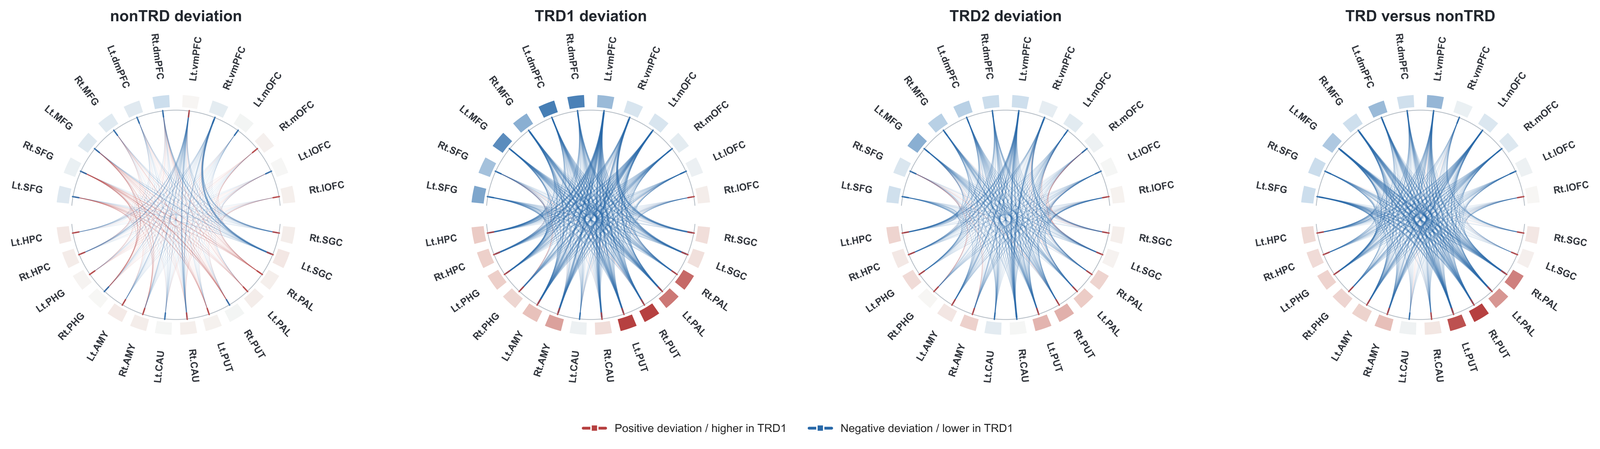

**`outputs/main_analyses/04_figures/corticolimbic_circular_nonTRD_mean_deviation.png`**

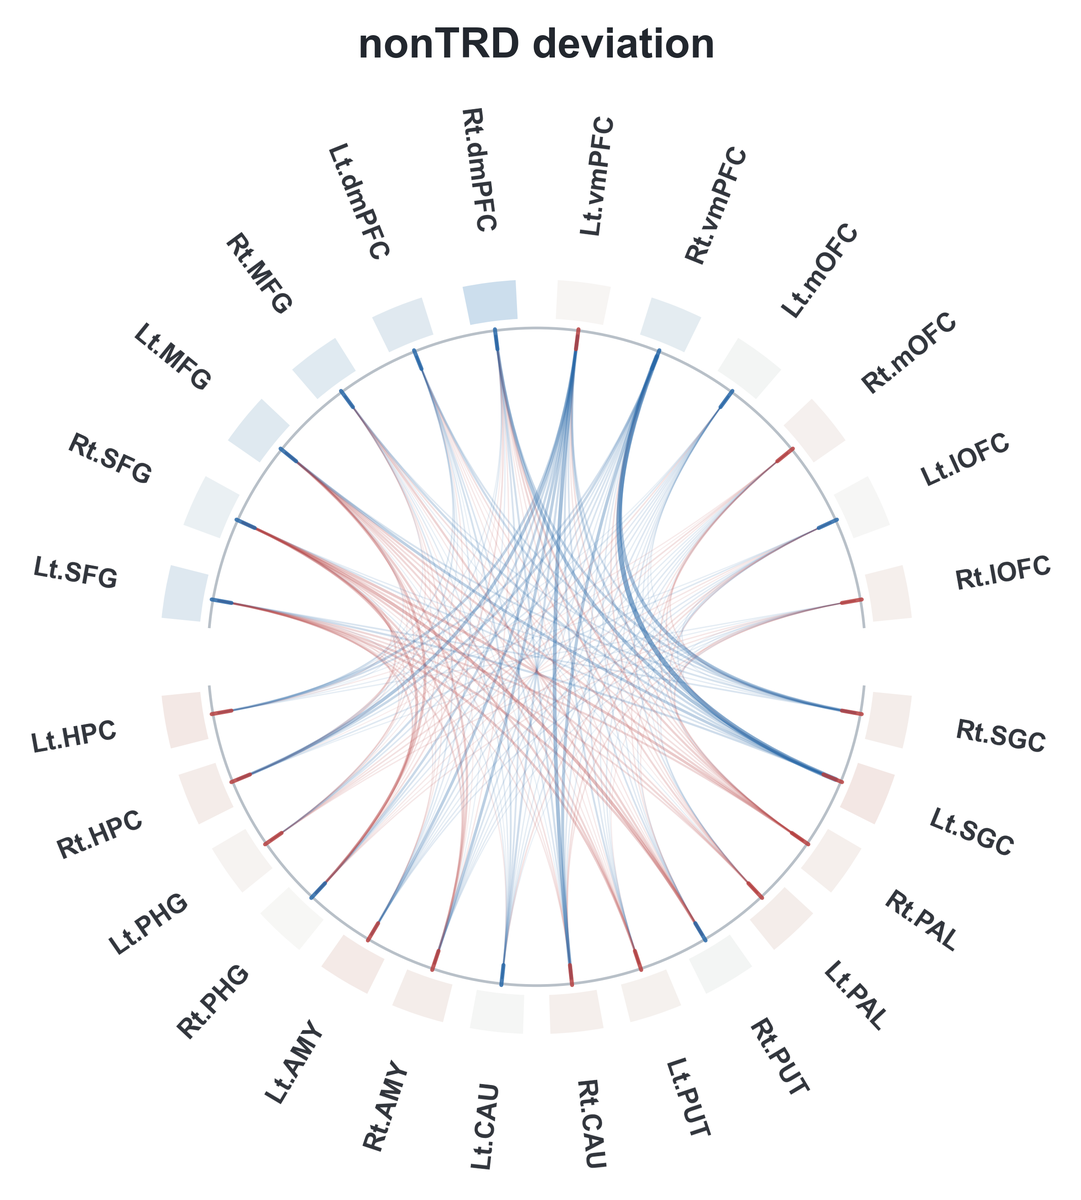

**`outputs/main_analyses/04_figures/corticolimbic_circular_TRD1_mean_deviation.png`**

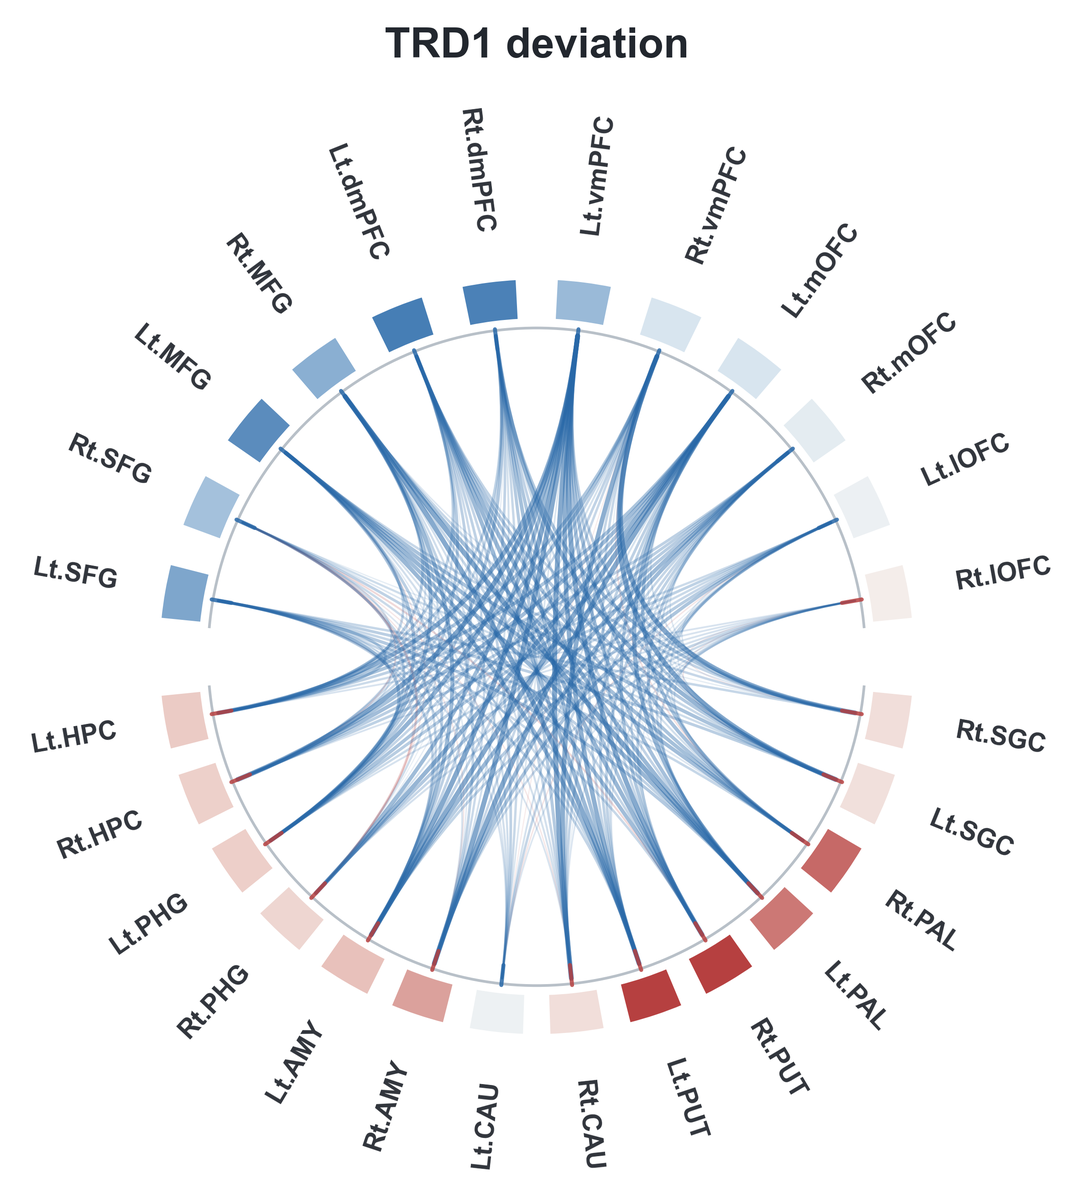

**`outputs/main_analyses/04_figures/corticolimbic_circular_TRD2_mean_deviation.png`**

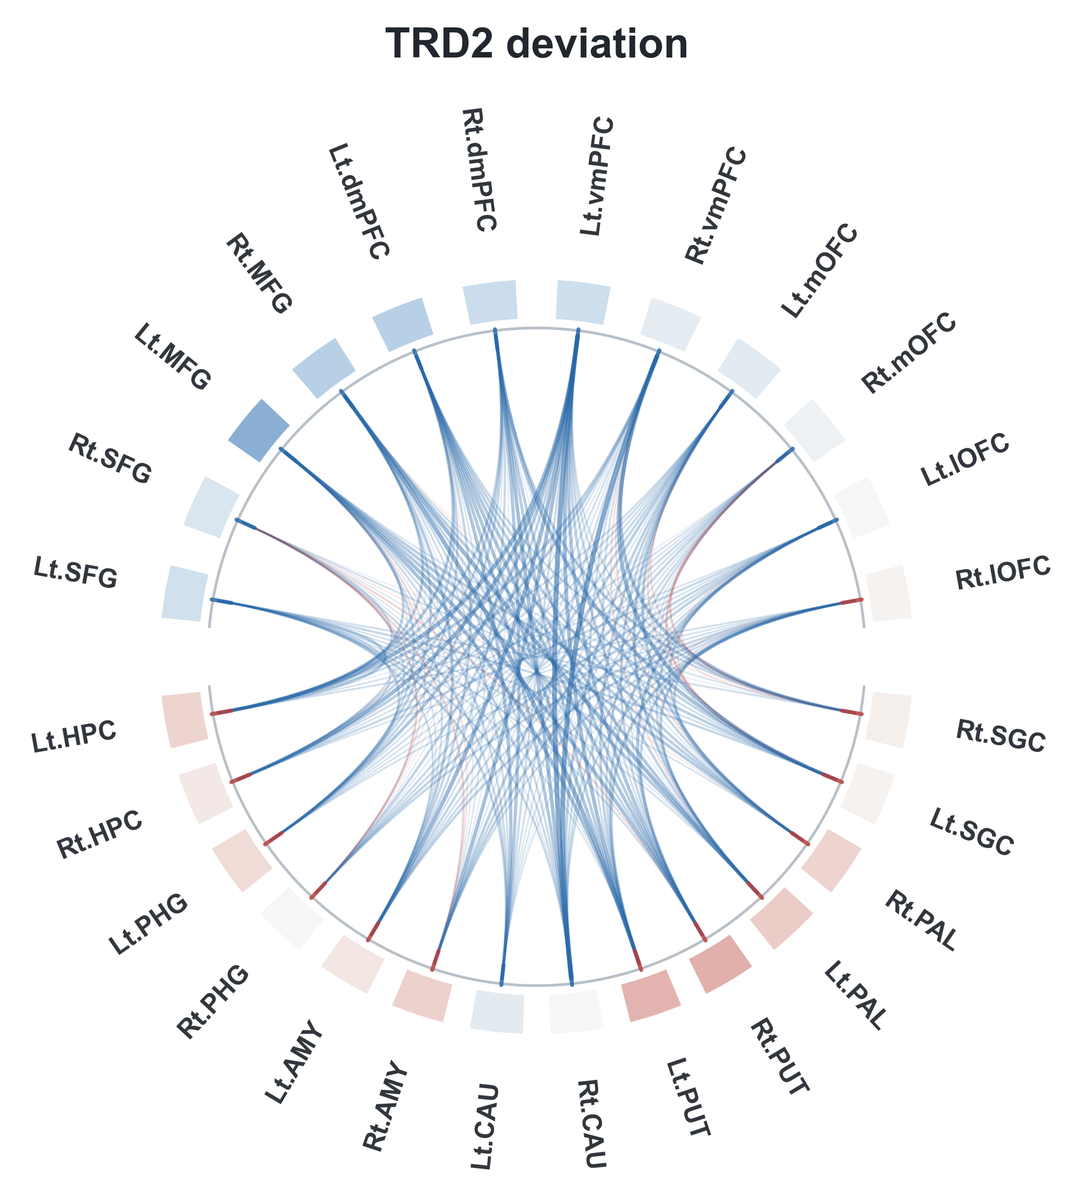

**`outputs/main_analyses/04_figures/corticolimbic_circular_TRD1_vs_nonTRD_all.png`**

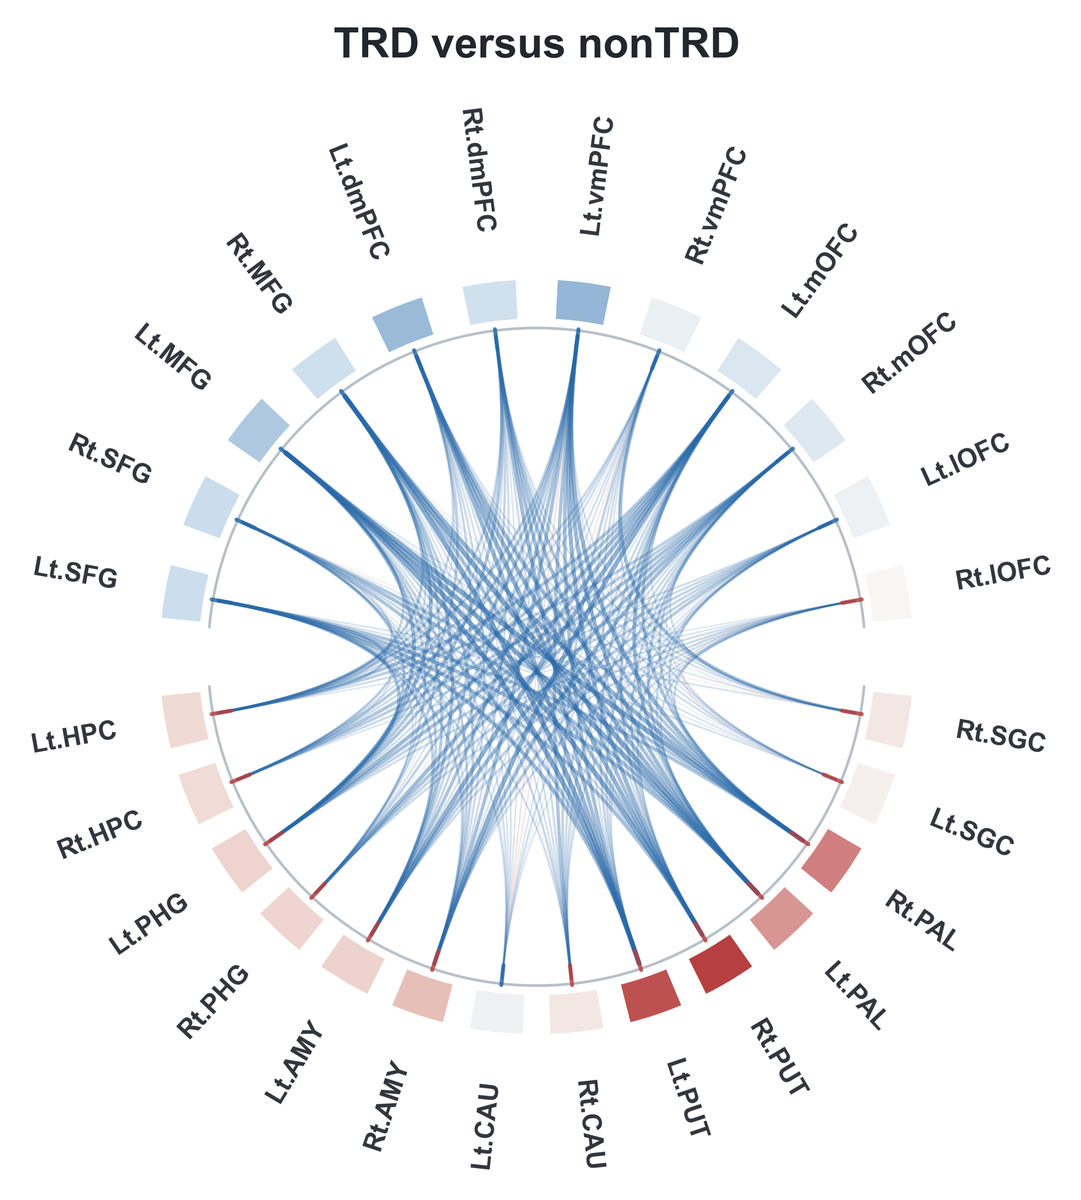

In [5]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'Cross-sectional regional node values', 'path': 'outputs/main_analyses/04_figures/corticolimbic_circular_plot_data.xlsx', 'sheet': 'regional_nodes', 'max_rows': 30}, {'title': 'Cross-sectional connectivity edge values', 'path': 'outputs/main_analyses/04_figures/corticolimbic_circular_plot_data.xlsx', 'sheet': 'connectivity_edges', 'max_rows': 30}]
_inline_figure_paths = ['outputs/main_analyses/04_figures/corticolimbic_circular_summary.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_nonTRD_mean_deviation.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_TRD1_mean_deviation.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_TRD2_mean_deviation.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_TRD1_vs_nonTRD_all.png']

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))
